# Machine Learning Task

## PCA-Based Breast Cancer Classification

### Objective

Apply Principal Component Analysis (PCA) to the Breast Cancer dataset and compare the performance of all studied Machine Learning models using 30 original features versus 2 principal components.

### Dataset

Use the Breast Cancer Wisconsin Diagnostic dataset from Scikit-learn.

* Number of samples: 569
* Number of features: 30
* Number of classes: 2 (Malignant and Benign)
* Problem type: Binary Classification

### Required Tasks

**1. Data Preparation**

* Load the dataset into a Pandas DataFrame.
* Separate features (X) and target (y).
* Split the data into 80% training and 20% testing.
* Use `random_state=42` and stratified splitting.
* Apply `StandardScaler` to the training and testing data.

**2. Experiment 1: Classification Using 30 Features**

Train and evaluate the following models using all 30 original features:

1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors (KNN)
4. Support Vector Machine (SVM)
5. Naive Bayes
6. Voting Classifier
7. Bagging Classifier
8. Random Forest
9. Gradient Boosting
10. AdaBoost
11. XGBoost

**3. Experiment 2: PCA with 2 Components**

* Apply PCA with `n_components=2`.
* Fit PCA on the scaled training data only.
* Transform both training and testing data.
* Display the explained variance ratio and cumulative explained variance ratio.
* Train and evaluate all 11 models using the 2 principal components.

**4. Model Evaluation**

For each model in both experiments, calculate:

* Accuracy
* Precision
* Recall
* F1-score
* Classification Report
* Confusion Matrix

**5. Results Comparison**

Create a single DataFrame comparing all models across both experiments.

The results must contain the following columns:

| Model               | Number of Features | Accuracy | Precision | Recall | F1-score |
| ------------------- | -----------------: | -------: | --------: | -----: | -------: |
| Logistic Regression |                 30 |          |           |        |          |
| Logistic Regression |                  2 |          |           |        |          |
| Decision Tree       |                 30 |          |           |        |          |
| Decision Tree       |                  2 |          |           |        |          |
| KNN                 |                 30 |          |           |        |          |
| KNN                 |                  2 |          |           |        |          |
| SVM                 |                 30 |          |           |        |          |
| SVM                 |                  2 |          |           |        |          |
| Naive Bayes         |                 30 |          |           |        |          |
| Naive Bayes         |                  2 |          |           |        |          |
| Voting Classifier   |                 30 |          |           |        |          |
| Voting Classifier   |                  2 |          |           |        |          |
| Bagging Classifier  |                 30 |          |           |        |          |
| Bagging Classifier  |                  2 |          |           |        |          |
| Random Forest       |                 30 |          |           |        |          |
| Random Forest       |                  2 |          |           |        |          |
| Gradient Boosting   |                 30 |          |           |        |          |
| Gradient Boosting   |                  2 |          |           |        |          |
| AdaBoost            |                 30 |          |           |        |          |
| AdaBoost            |                  2 |          |           |        |          |
| XGBoost             |                 30 |          |           |        |          |
| XGBoost             |                  2 |          |           |        |          |

**6. Visualization**

Create the following visualizations:

* Grouped bar chart comparing the Accuracy of all models using 30 features and 2 PCA components.
* Grouped bar chart comparing the F1-score of all models using both approaches.
* Scatter plot of the two principal components, with different colors representing the two target classes.

### Submission

Submit a Jupyter Notebook containing the complete implementation, evaluation results, comparison DataFrame, and visualizations.

**Important:** Use the same train-test split for both experiments. Fit the scaler and PCA using training data only, then transform the testing data using the fitted objects.


---
## 0. Imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import (VotingClassifier, BaggingClassifier, RandomForestClassifier,
                              GradientBoostingClassifier, AdaBoostClassifier)
from xgboost import XGBClassifier

RANDOM_STATE = 42
sns.set_style("whitegrid")

---
## 1. Data Preparation

In [2]:

data = load_breast_cancer(as_frame=True)
df = data.frame

print("Shape:", df.shape)
print("Target mapping:", dict(enumerate(data.target_names)))
print(df["target"].value_counts())
df.head()

Shape: (569, 31)
Target mapping: {0: np.str_('malignant'), 1: np.str_('benign')}
target
1    357
0    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:

X = df.drop(columns="target")
y = df["target"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train_scaled.shape, "| Test:", X_test_scaled.shape)

Train: (455, 30) | Test: (114, 30)


---
## 2. Helper Functions & Models


In [4]:
POS_LABEL = 1
target_names = list(data.target_names)

def get_models():

    return {
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
        "KNN": KNeighborsClassifier(n_neighbors=5),
        "SVM": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
        "Naive Bayes": GaussianNB(),
        "Voting Classifier": VotingClassifier(
            estimators=[
                ("lr", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
                ("svm", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)),
                ("rf", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)),
            ],
            voting="soft",
        ),
        "Bagging Classifier": BaggingClassifier(
            estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
            n_estimators=100, random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
        "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
        "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=RANDOM_STATE),
        "XGBoost": XGBClassifier(n_estimators=100, eval_metric="logloss", random_state=RANDOM_STATE),
    }


def evaluate_model(name, model, X_tr, X_te, y_tr, y_te, n_features, show=True):

    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    metrics = {
        "Model": name,
        "Number of Features": n_features,
        "Accuracy": accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred, pos_label=POS_LABEL),
        "Recall": recall_score(y_te, y_pred, pos_label=POS_LABEL),
        "F1-score": f1_score(y_te, y_pred, pos_label=POS_LABEL),
    }
    cm = confusion_matrix(y_te, y_pred)

    if show:
        print("=" * 70)
        print(f"{name}  |  Features: {n_features}")
        print("=" * 70)
        print(classification_report(y_te, y_pred, target_names=target_names))
        print("Confusion Matrix:\n", cm, "\n")
    return metrics, cm


def run_experiment(X_tr, X_te, y_tr, y_te, n_features):
    results, cms = [], {}
    for name, model in get_models().items():
        m, cm = evaluate_model(name, model, X_tr, X_te, y_tr, y_te, n_features)
        results.append(m)
        cms[name] = cm
    return results, cms


def plot_confusion_matrices(cms, title):
    fig, axes = plt.subplots(3, 4, figsize=(18, 12))
    for ax, (name, cm) in zip(axes.ravel(), cms.items()):
        ConfusionMatrixDisplay(cm, display_labels=target_names).plot(ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(name)
    for ax in axes.ravel()[len(cms):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

---
## 3. Experiment 1: Classification Using 30 Features

In [5]:
results_30, cms_30 = run_experiment(X_train_scaled, X_test_scaled, y_train, y_test, n_features=30)

Logistic Regression  |  Features: 30
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Confusion Matrix:
 [[41  1]
 [ 1 71]] 

Decision Tree  |  Features: 30
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114

Confusion Matrix:
 [[39  3]
 [ 7 65]] 

KNN  |  Features: 30
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy 

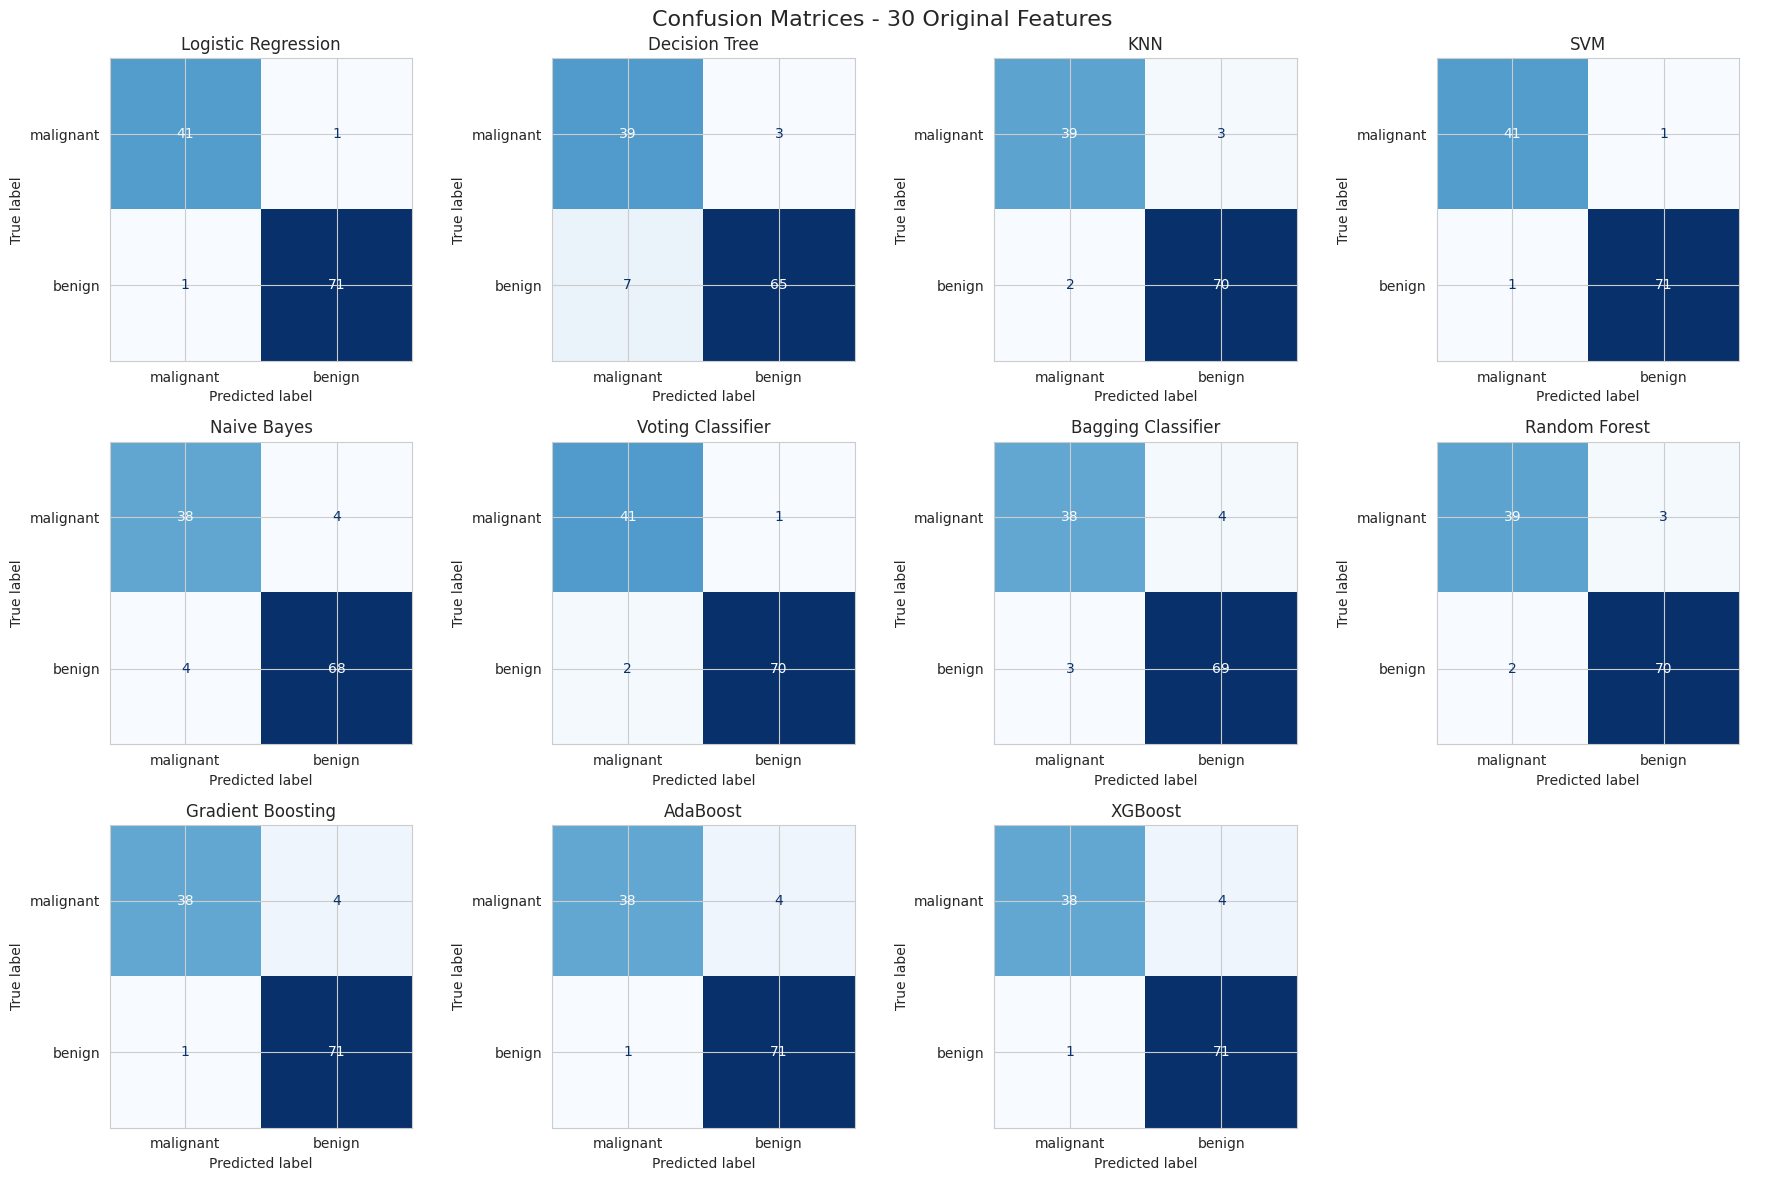

In [7]:
plot_confusion_matrices(cms_30, "Confusion Matrices - 30 Original Features")

---
## 4. Experiment 2: PCA with 2 Components

In [8]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

evr = pca.explained_variance_ratio_
cum_evr = np.cumsum(evr)

variance_df = pd.DataFrame({
    "Component": ["PC1", "PC2"],
    "Explained Variance Ratio": evr,
    "Cumulative Explained Variance": cum_evr,
})
display(variance_df)
print(f"Two components keep {cum_evr[-1]*100:.2f}% of the total variance "
      f"(information lost: {(1-cum_evr[-1])*100:.2f}%)")

,Component,Explained Variance Ratio,Cumulative Explained Variance
0,PC1,0.444135,0.444135
1,PC2,0.189446,0.633581


Two components keep 63.36% of the total variance (information lost: 36.64%)


In [9]:
results_2, cms_2 = run_experiment(X_train_pca, X_test_pca, y_train, y_test, n_features=2)

Logistic Regression  |  Features: 2
              precision    recall  f1-score   support

   malignant       0.91      0.95      0.93        42
      benign       0.97      0.94      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.95      0.94       114
weighted avg       0.95      0.95      0.95       114

Confusion Matrix:
 [[40  2]
 [ 4 68]] 

Decision Tree  |  Features: 2
              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114

Confusion Matrix:
 [[38  4]
 [ 3 69]] 

KNN  |  Features: 2
              precision    recall  f1-score   support

   malignant       0.88      0.90      0.89        42
      benign       0.94      0.93      0.94        72

    accuracy    

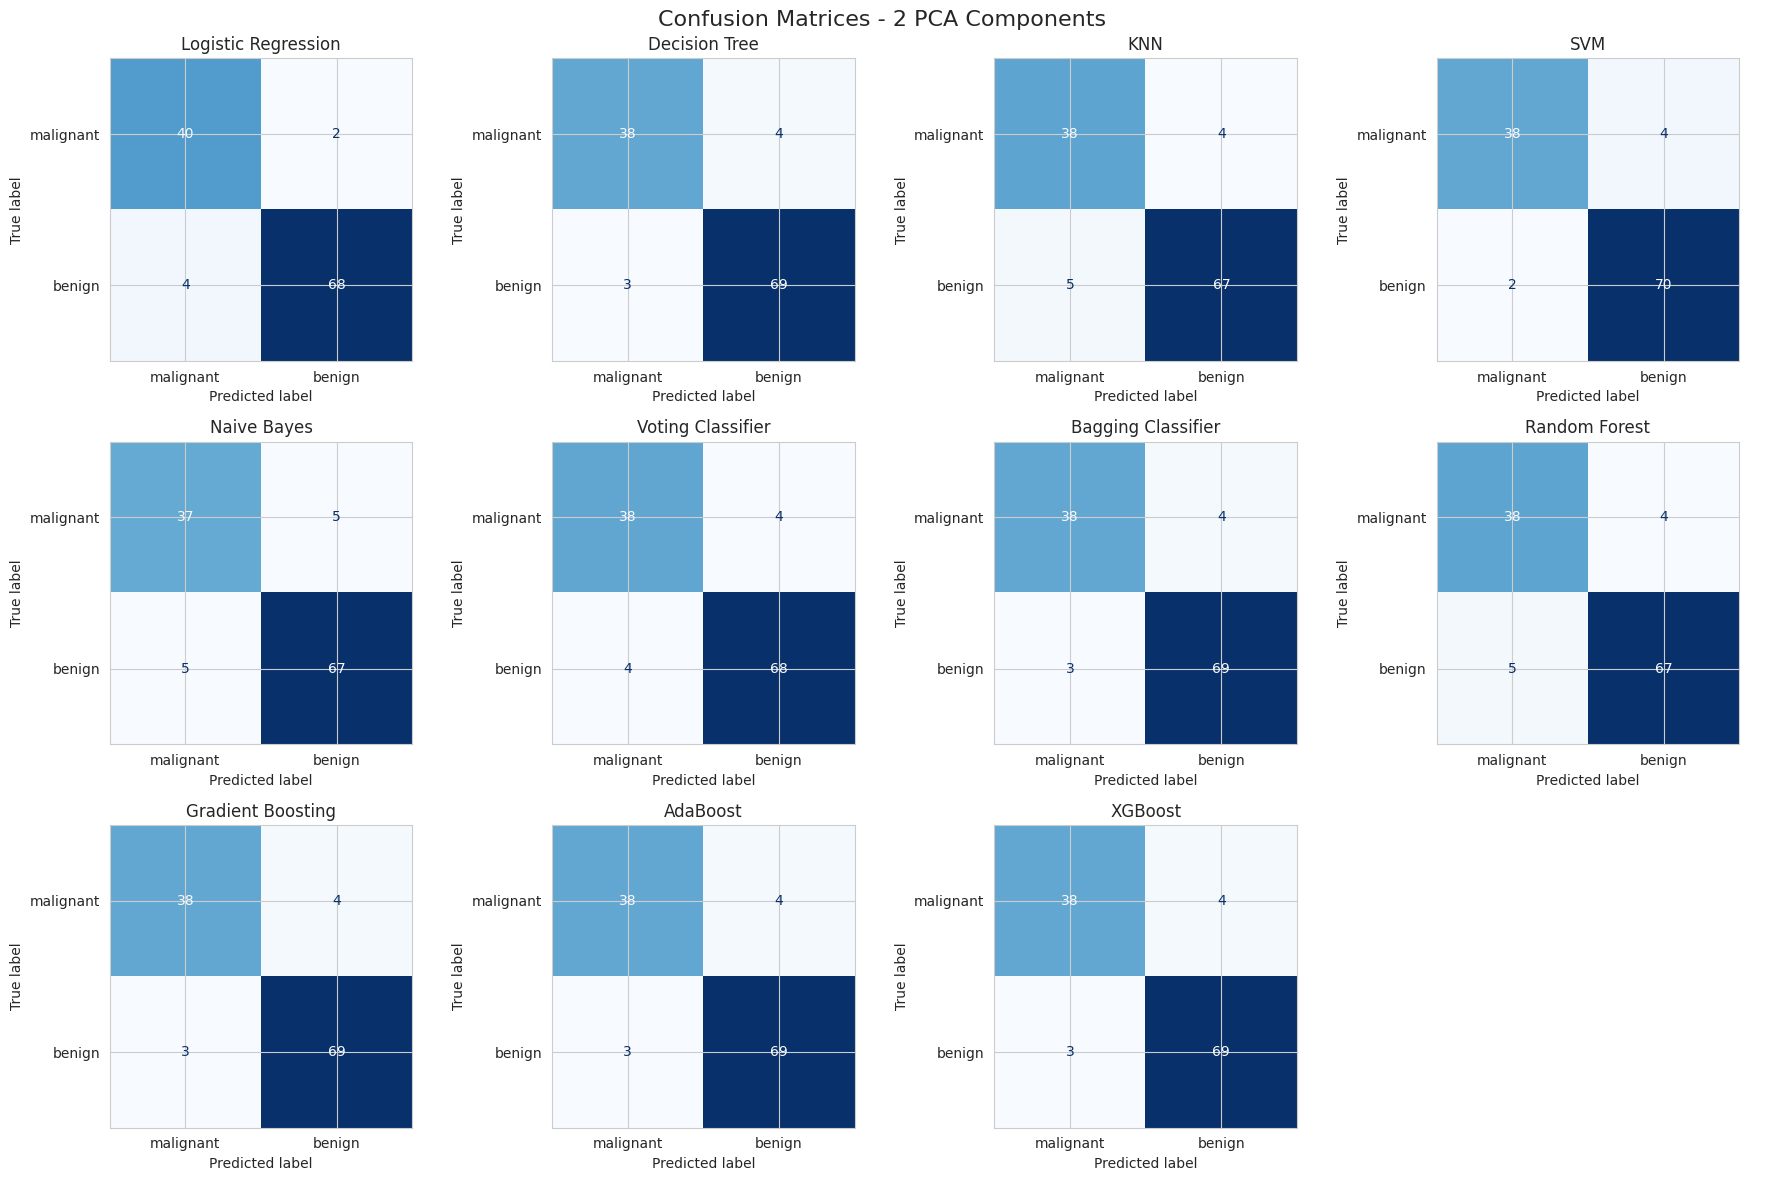

In [11]:
plot_confusion_matrices(cms_2, "Confusion Matrices - 2 PCA Components")

---
## 5. Results Comparison

In [12]:
results_df = pd.DataFrame(results_30 + results_2)

# Order: each model with 30 then 2 features (as in the task table)
model_order = list(get_models().keys())
results_df["Model"] = pd.Categorical(results_df["Model"], categories=model_order, ordered=True)
results_df = (results_df.sort_values(["Model", "Number of Features"], ascending=[True, False])
                        .reset_index(drop=True))
results_df["Model"] = results_df["Model"].astype(str)

metric_cols = ["Accuracy", "Precision", "Recall", "F1-score"]
results_df[metric_cols] = results_df[metric_cols].round(4)
results_df

,Model,Number of Features,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,30,0.9825,0.9861,0.9861,0.9861
1,Logistic Regression,2,0.9474,0.9714,0.9444,0.9577
2,Decision Tree,30,0.9123,0.9559,0.9028,0.9286
3,Decision Tree,2,0.9386,0.9452,0.9583,0.9517
4,KNN,30,0.9561,0.9589,0.9722,0.9655
5,KNN,2,0.9211,0.9437,0.9306,0.9371
6,SVM,30,0.9825,0.9861,0.9861,0.9861
7,SVM,2,0.9474,0.9459,0.9722,0.9589
8,Naive Bayes,30,0.9298,0.9444,0.9444,0.9444
9,Naive Bayes,2,0.9123,0.9306,0.9306,0.9306


In [13]:
pivot = results_df.pivot(index="Model", columns="Number of Features", values="Accuracy").loc[model_order]
pivot["Drop (30 -> 2)"] = (pivot[30] - pivot[2]).round(4)
pivot

Number of Features,2,30,Drop (30 -> 2)
Model,,,
Logistic Regression,0.9474,0.9825,0.0351
Decision Tree,0.9386,0.9123,-0.0263
KNN,0.9211,0.9561,0.0350
SVM,0.9474,0.9825,0.0351
Naive Bayes,0.9123,0.9298,0.0175
Voting Classifier,0.9298,0.9737,0.0439
Bagging Classifier,0.9386,0.9386,0.0000
Random Forest,0.9211,0.9561,0.0350
Gradient Boosting,0.9386,0.9561,0.0175


---
## 6. Visualization

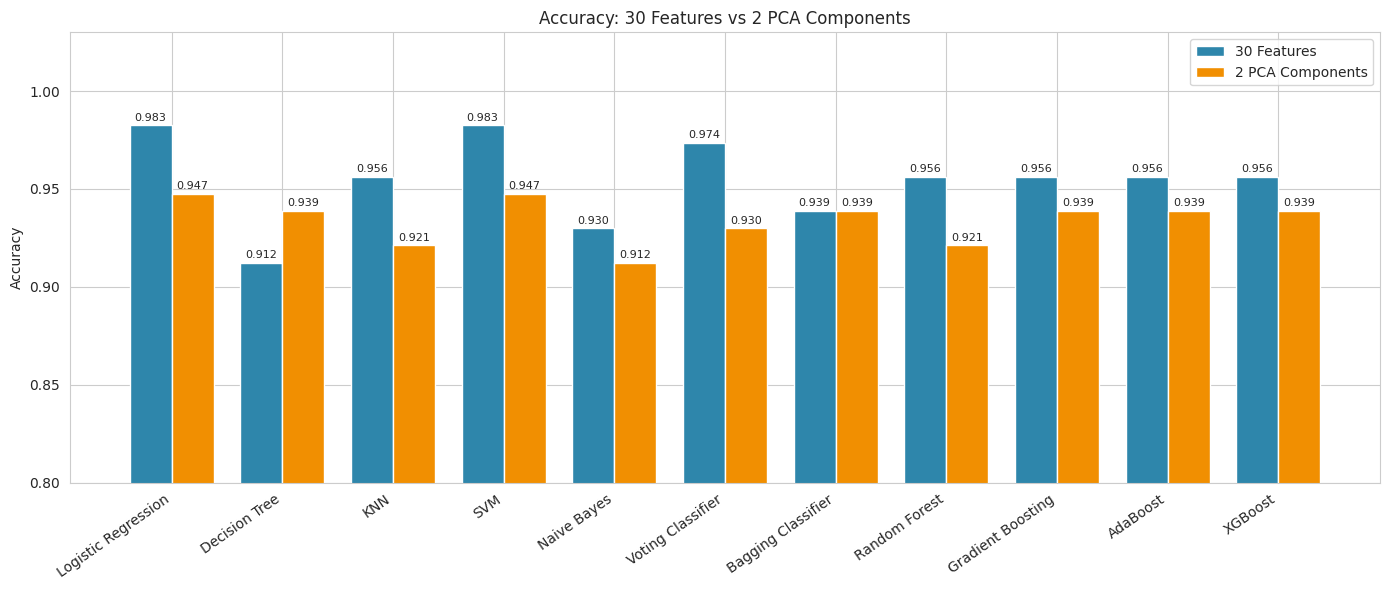

In [14]:
def grouped_bar(metric):
    plot_df = results_df.pivot(index="Model", columns="Number of Features", values=metric).loc[model_order]
    x = np.arange(len(model_order))
    w = 0.38

    fig, ax = plt.subplots(figsize=(14, 6))
    b1 = ax.bar(x - w/2, plot_df[30], w, label="30 Features", color="#2E86AB")
    b2 = ax.bar(x + w/2, plot_df[2], w, label="2 PCA Components", color="#F18F01")
    ax.bar_label(b1, fmt="%.3f", fontsize=8, padding=2)
    ax.bar_label(b2, fmt="%.3f", fontsize=8, padding=2)

    ax.set_xticks(x)
    ax.set_xticklabels(model_order, rotation=35, ha="right")
    ax.set_ylabel(metric)
    ax.set_ylim(0.8, 1.03)
    ax.set_title(f"{metric}: 30 Features vs 2 PCA Components")
    ax.legend()
    plt.tight_layout()
    plt.show()

grouped_bar("Accuracy")

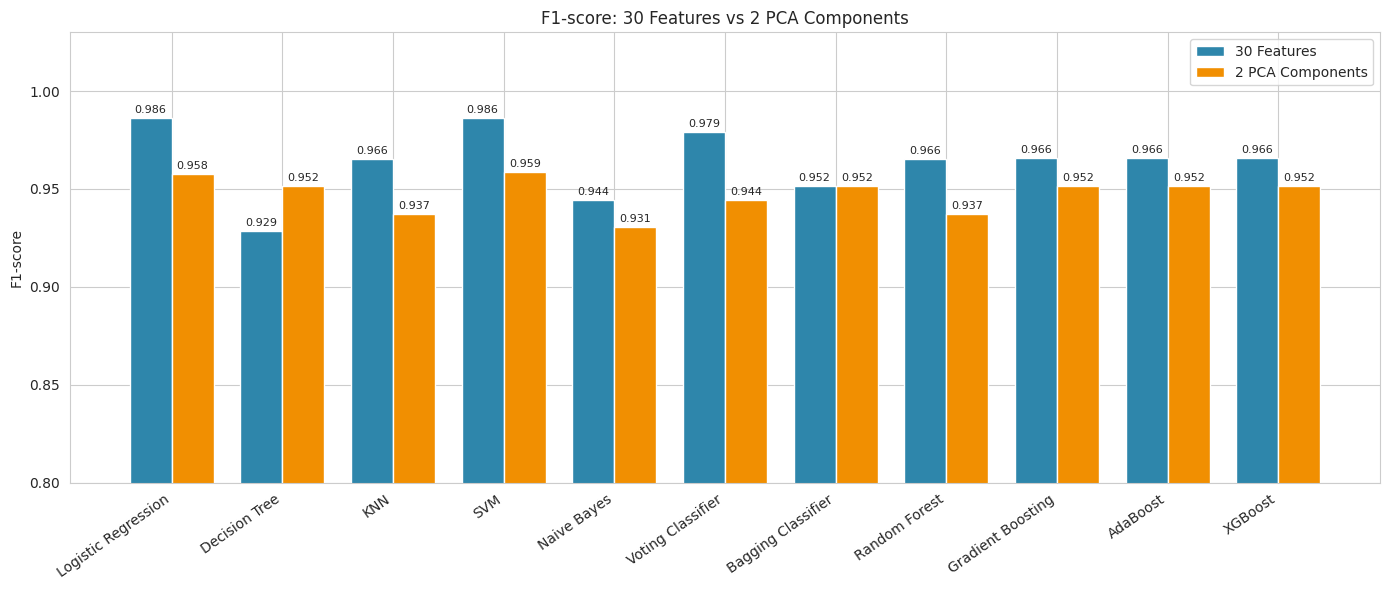

In [15]:
grouped_bar("F1-score")

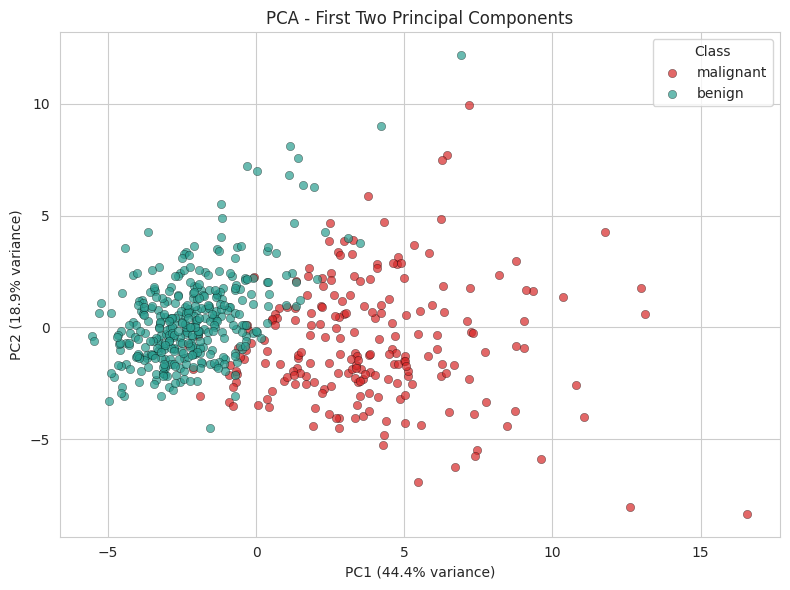

In [16]:
X_pca_all = np.vstack([X_train_pca, X_test_pca])
y_all = np.concatenate([y_train.values, y_test.values])

plt.figure(figsize=(8, 6))
for label, color in zip([0, 1], ["#D62828", "#2A9D8F"]):
    mask = y_all == label
    plt.scatter(X_pca_all[mask, 0], X_pca_all[mask, 1], c=color, alpha=0.7,
                edgecolor="k", linewidth=0.3, label=target_names[label])
plt.xlabel(f"PC1 ({evr[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({evr[1]*100:.1f}% variance)")
plt.title("PCA - First Two Principal Components")
plt.legend(title="Class")
plt.tight_layout()
plt.show()

---
## 7. Conclusions

In [17]:
best_30 = results_df[results_df["Number of Features"] == 30].sort_values("F1-score", ascending=False).iloc[0]
best_2 = results_df[results_df["Number of Features"] == 2].sort_values("F1-score", ascending=False).iloc[0]
print(f"Best with 30 features : {best_30['Model']} (Acc={best_30['Accuracy']}, F1={best_30['F1-score']})")
print(f"Best with 2 components: {best_2['Model']} (Acc={best_2['Accuracy']}, F1={best_2['F1-score']})")
print(f"Mean accuracy  30 features: {results_df[results_df['Number of Features']==30]['Accuracy'].mean():.4f}")
print(f"Mean accuracy  2 components: {results_df[results_df['Number of Features']==2]['Accuracy'].mean():.4f}")

Best with 30 features : Logistic Regression (Acc=0.9825, F1=0.9861)
Best with 2 components: SVM (Acc=0.9474, F1=0.9589)
Mean accuracy  30 features: 0.9545
Mean accuracy  2 components: 0.9338
